# Projeto de Aprendizado de Máquina
## Classificação de variedades de arroz: Cammeo e Osmancik

**Grupo:** 8 - D3

**Integrante:** Rafaela Ferreira dos Santos - CP3026353

**Disciplina:** Introdução ao Aprendizado de Máquina

**Professor:** Everton Meyer da Silva

### Objetivo

O objetivo deste projeto é utilizar aprendizado de máquina para identificar duas variedades de arroz: Cammeo e Osmancik. Para isso, serão utilizadas algumas características físicas dos grãos, como área, perímetro, comprimento e largura.

1. importar os dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os arquivos CSV
df_train = pd.read_csv("/content/rice_train.csv")
df_test = pd.read_csv("/content/rice_test.csv")

# Mostrar as primeiras linhas
display(df_train.head())

# Verificar o tamanho dos arquivos
print("Treinamento:", df_train.shape)
print("Teste:", df_test.shape)


,area,perimeter,major_axis_length,minor_axis_length,eccentricity,convex_area,extent,variety
0,13078,452.990997,183.978973,91.690010,0.866963,13385,0.732743,osmancik
1,15381,503.579010,211.883530,93.309746,0.897810,15749,0.740325,cammeo
2,11280,420.101013,170.670364,85.497368,0.865476,11582,0.643175,osmancik
3,12408,454.390991,191.896530,83.033478,0.901538,12664,0.583906,osmancik
4,14131,490.700989,206.926666,88.284050,0.904420,14519,0.752931,cammeo


Treinamento: (3048, 8)
Teste: (762, 8)


Etapa 2 — Preparação dos dados

# 1. Preparação dos Dados

Nesta primeira etapa, foi feita uma análise inicial da base de dados. Foram verificadas a quantidade de registros, as características das colunas, a existência de valores ausentes, registros duplicados e possíveis valores fora do padrão.

O conjunto de treinamento será utilizado para desenvolver os modelos, enquanto o conjunto de teste ficará separado para a avaliação final.

In [2]:
# Verificar a quantidade de linhas e colunas
print("Dimensões do treinamento:", df_train.shape)

# Verificar os tipos das colunas
print("\nTipos das variáveis:")
print(df_train.dtypes)

# Verificar informações gerais
print("\nInformações da base:")
df_train.info()

# Visualizar as primeiras linhas
display(df_train.head())

Dimensões do treinamento: (3048, 8)

Tipos das variáveis:
area                   int64
perimeter            float64
major_axis_length    float64
minor_axis_length    float64
eccentricity         float64
convex_area            int64
extent               float64
variety               object
dtype: object

Informações da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3048 entries, 0 to 3047
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   area               3048 non-null   int64  
 1   perimeter          3048 non-null   float64
 2   major_axis_length  3048 non-null   float64
 3   minor_axis_length  3048 non-null   float64
 4   eccentricity       3048 non-null   float64
 5   convex_area        3048 non-null   int64  
 6   extent             3048 non-null   float64
 7   variety            3048 non-null   object 
dtypes: float64(5), int64(2), object(1)
memory usage: 190.6+ KB


,area,perimeter,major_axis_length,minor_axis_length,eccentricity,convex_area,extent,variety
0,13078,452.990997,183.978973,91.690010,0.866963,13385,0.732743,osmancik
1,15381,503.579010,211.883530,93.309746,0.897810,15749,0.740325,cammeo
2,11280,420.101013,170.670364,85.497368,0.865476,11582,0.643175,osmancik
3,12408,454.390991,191.896530,83.033478,0.901538,12664,0.583906,osmancik
4,14131,490.700989,206.926666,88.284050,0.904420,14519,0.752931,cammeo


3. Verificar valores ausentes e duplicados

In [3]:
# Verificar valores ausentes
print("Valores ausentes por coluna:")
print(df_train.isnull().sum())

# Verificar quantidade total de valores ausentes
print("\nTotal de valores ausentes:")
print(df_train.isnull().sum().sum())

# Verificar registros duplicados
print("\nQuantidade de registros duplicados:")
print(df_train.duplicated().sum())

Valores ausentes por coluna:
area                 0
perimeter            0
major_axis_length    0
minor_axis_length    0
eccentricity         0
convex_area          0
extent               0
variety              0
dtype: int64

Total de valores ausentes:
0

Quantidade de registros duplicados:
0


4. Verificar valores inválidos





In [4]:
# Selecionar somente as colunas numéricas
colunas_numericas = df_train.select_dtypes(include=np.number).columns

# Contar valores menores ou iguais a zero
for coluna in colunas_numericas:
    quantidade = (df_train[coluna] <= 0).sum()
    print(f"{coluna}: {quantidade} valores menores ou iguais a zero")

area: 0 valores menores ou iguais a zero
perimeter: 0 valores menores ou iguais a zero
major_axis_length: 0 valores menores ou iguais a zero
minor_axis_length: 0 valores menores ou iguais a zero
eccentricity: 0 valores menores ou iguais a zero
convex_area: 0 valores menores ou iguais a zero
extent: 0 valores menores ou iguais a zero


5. Analisar possíveis outliers: Outliers são valores muito diferentes da maioria dos registros.

In [5]:
# Identificar possíveis outliers pelo método IQR

for coluna in colunas_numericas:
    Q1 = df_train[coluna].quantile(0.25)
    Q3 = df_train[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df_train[
        (df_train[coluna] < limite_inferior) |
        (df_train[coluna] > limite_superior)
    ]

    print(f"{coluna}: {len(outliers)} possíveis outliers")

area: 2 possíveis outliers
perimeter: 0 possíveis outliers
major_axis_length: 0 possíveis outliers
minor_axis_length: 57 possíveis outliers
eccentricity: 14 possíveis outliers
convex_area: 1 possíveis outliers
extent: 0 possíveis outliers


### Conclusão da preparação

Na análise inicial, não foram encontrados valores ausentes, registros duplicados ou valores numéricos menores ou iguais a zero.

Também foram encontrados alguns possíveis outliers, principalmente na característica minor_axis_length. Esses valores foram mantidos, pois podem representar diferenças naturais no tamanho dos grãos.

Assim, a base foi mantida para as próximas etapas do projeto, sem excluir informações que poderiam ser importantes.

# 2. Análise Exploratória dos Dados (EDA)

Nesta etapa, foi feita uma análise dos dados para entender melhor as características dos grãos das duas variedades.

Foram utilizados gráficos e comparações para observar a distribuição dos dados, as diferenças entre Cammeo e Osmancik e a relação entre as características físicas.

In [6]:
# Configurações dos gráficos
sns.set_theme(style="whitegrid")

# Conferir a quantidade de registros por variedade
print("Quantidade de grãos por variedade:")
print(df_train["variety"].value_counts())

Quantidade de grãos por variedade:
variety
osmancik    1744
cammeo      1304
Name: count, dtype: int64


### Pergunta 1: Quantos grãos de cada variedade existem na base?

Essa análise foi feita para verificar a quantidade de registros de cada variedade e observar se existe uma diferença muito grande entre as classes.

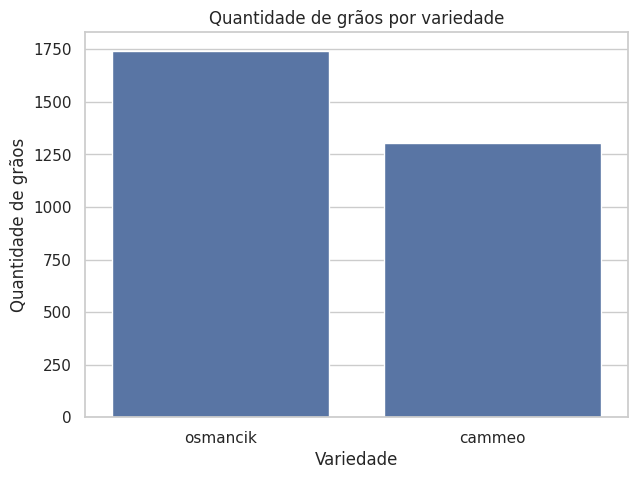

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_train, x="variety")

plt.title("Quantidade de grãos por variedade")
plt.xlabel("Variedade")
plt.ylabel("Quantidade de grãos")

plt.show()

**Análise:**

A base possui 1.744 registros da variedade Osmancik e 1.304 da variedade Cammeo. Isso representa aproximadamente 57,22% e 42,78% dos dados, respectivamente.

A variedade Osmancik possui mais registros, mas a diferença entre as duas quantidades não é muito grande.

### Pergunta 2: Qual é a distribuição da área dos grãos?

A área é uma das características utilizadas para diferenciar os grãos. O histograma ajuda a observar quais valores aparecem com mais frequência e como eles estão distribuídos.



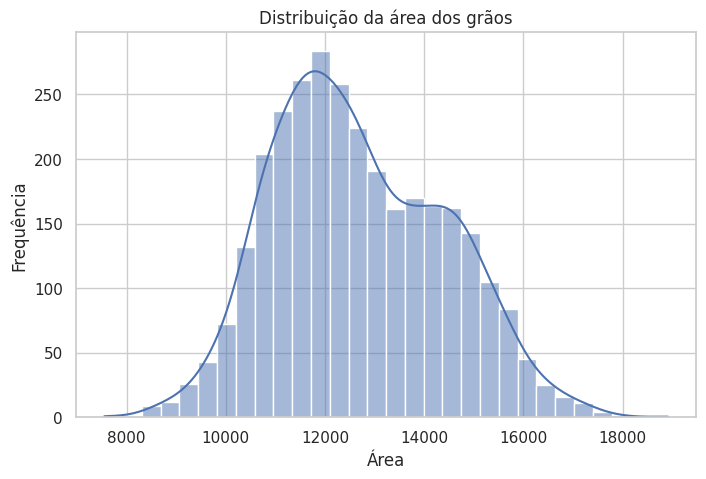

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_train, x="area", bins=30, kde=True)

plt.title("Distribuição da área dos grãos")
plt.xlabel("Área")
plt.ylabel("Frequência")

plt.show()

**Análise:**

O gráfico mostra que os valores de área não estão todos concentrados em um único ponto. Existe uma variação entre os tamanhos dos grãos, com maior concentração em algumas faixas de valores.

Isso ajuda a entender melhor como essa característica aparece na base de dados.


### Pergunta 3: Qual variedade apresenta maior área média?

Nesta análise, foram comparadas as áreas médias dos grãos Cammeo e Osmancik para verificar qual variedade apresenta grãos maiores nessa característica.

Área média por variedade:
variety
cammeo      14182.992331
osmancik    11553.939220
Name: area, dtype: float64


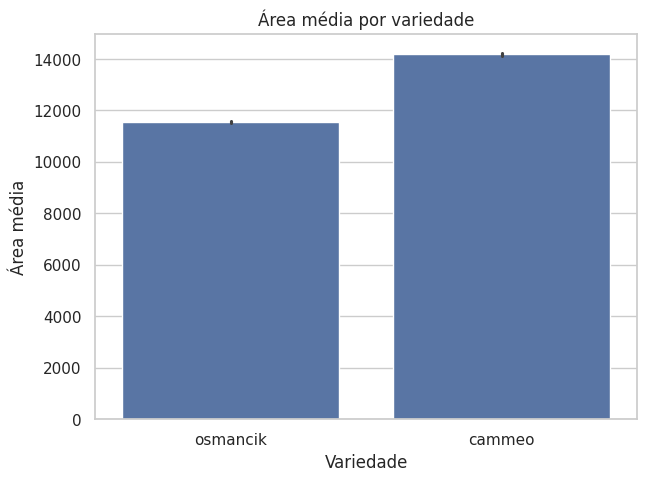

In [9]:
media_area = df_train.groupby("variety")["area"].mean()

print("Área média por variedade:")
print(media_area)

plt.figure(figsize=(7, 5))

sns.barplot(data=df_train, x="variety", y="area")

plt.title("Área média por variedade")
plt.xlabel("Variedade")
plt.ylabel("Área média")

plt.show()

**Análise:**

A variedade Cammeo apresenta área média de aproximadamente 14.183, enquanto a variedade Osmancik apresenta aproximadamente 11.554.

Isso mostra que, em média, os grãos Cammeo possuem uma área maior que os grãos Osmancik.

### Pergunta 4: Existe diferença no comprimento dos grãos entre as variedades?

Aqui foi comparado o comprimento do eixo maior (major_axis_length) dos grãos das duas variedades.

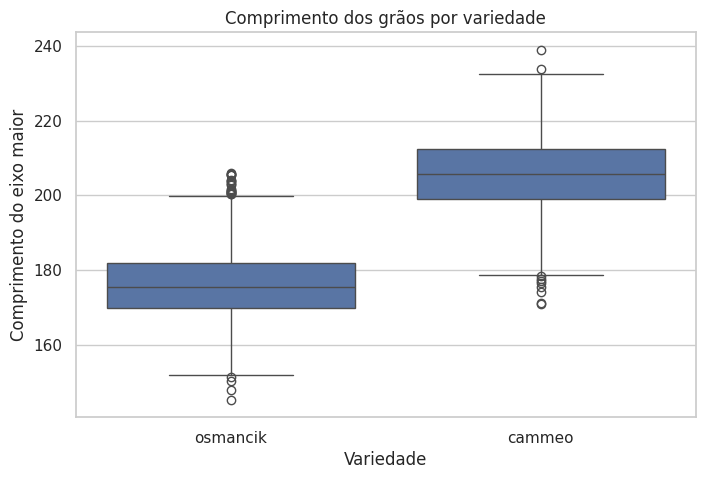

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_train, x="variety", y="major_axis_length")

plt.title("Comprimento dos grãos por variedade")
plt.xlabel("Variedade")
plt.ylabel("Comprimento do eixo maior")

plt.show()

**Análise:**

Pelo gráfico, é possível perceber que os grãos Cammeo geralmente apresentam valores maiores de comprimento que os grãos Osmancik.

As medianas também mostram essa diferença. Isso indica que o comprimento do grão pode ajudar a identificar a variedade.

### Pergunta 5: Qual é a relação entre a área e o perímetro dos grãos?

Nesta análise, foi verificado se os grãos com maior área também costumam apresentar um perímetro maior.

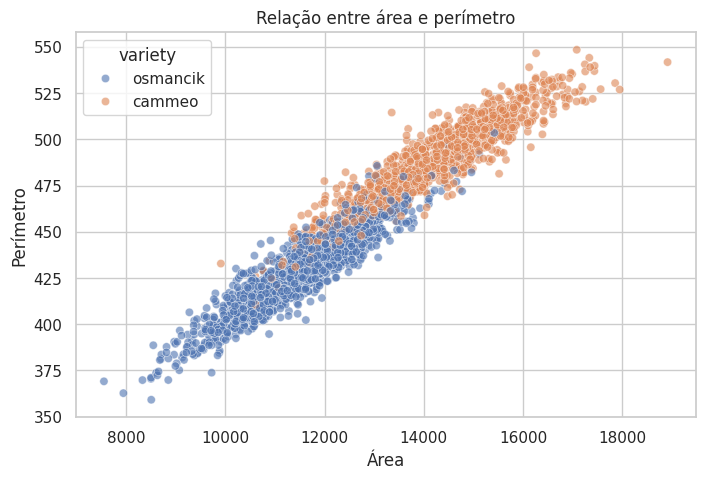

Correlação entre área e perímetro:
0.9667240526547929


In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_train,
    x="area",
    y="perimeter",
    hue="variety",
    alpha=0.6
)

plt.title("Relação entre área e perímetro")
plt.xlabel("Área")
plt.ylabel("Perímetro")

plt.show()

# Calcular a correlação
print("Correlação entre área e perímetro:")
print(df_train["area"].corr(df_train["perimeter"]))

**Análise:**

O gráfico mostra que existe uma relação positiva entre a área e o perímetro. Isso significa que, geralmente, quando a área aumenta, o perímetro também aumenta.

A correlação encontrada foi de aproximadamente 0,97, indicando uma relação muito forte entre essas duas características.

### Pergunta 6: Existe correlação entre o comprimento e a largura dos grãos?

Nesta análise, foram comparados o eixo maior e o eixo menor dos grãos para verificar se essas duas características apresentam alguma relação.

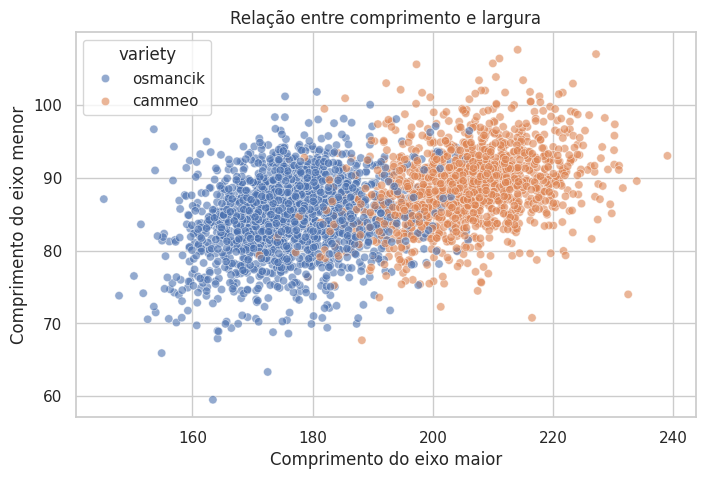

Correlação:
0.44606127984150584


In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_train,
    x="major_axis_length",
    y="minor_axis_length",
    hue="variety",
    alpha=0.6
)

plt.title("Relação entre comprimento e largura")
plt.xlabel("Comprimento do eixo maior")
plt.ylabel("Comprimento do eixo menor")

plt.show()

print("Correlação:")
print(df_train["major_axis_length"].corr(
    df_train["minor_axis_length"]
))


**Análise:**

O gráfico mostra que existe uma relação positiva entre o comprimento e a largura dos grãos.

A correlação encontrada foi de aproximadamente 0,73. Isso indica que as duas características estão relacionadas, mas essa relação é menos forte do que a encontrada entre área e perímetro.

### Pergunta 7: Quais características apresentam maior diferença entre as variedades?

Nesta parte, foram comparadas as médias das características físicas para observar quais delas apresentam diferenças maiores entre Cammeo e Osmancik.

Médias das características por variedade:


,area,perimeter,major_axis_length,minor_axis_length,eccentricity,convex_area,extent
variety,,,,,,,
cammeo,14182.99,487.87,205.60,88.86,0.90,14516.98,0.65
osmancik,11553.94,429.33,176.17,84.56,0.88,11803.76,0.67


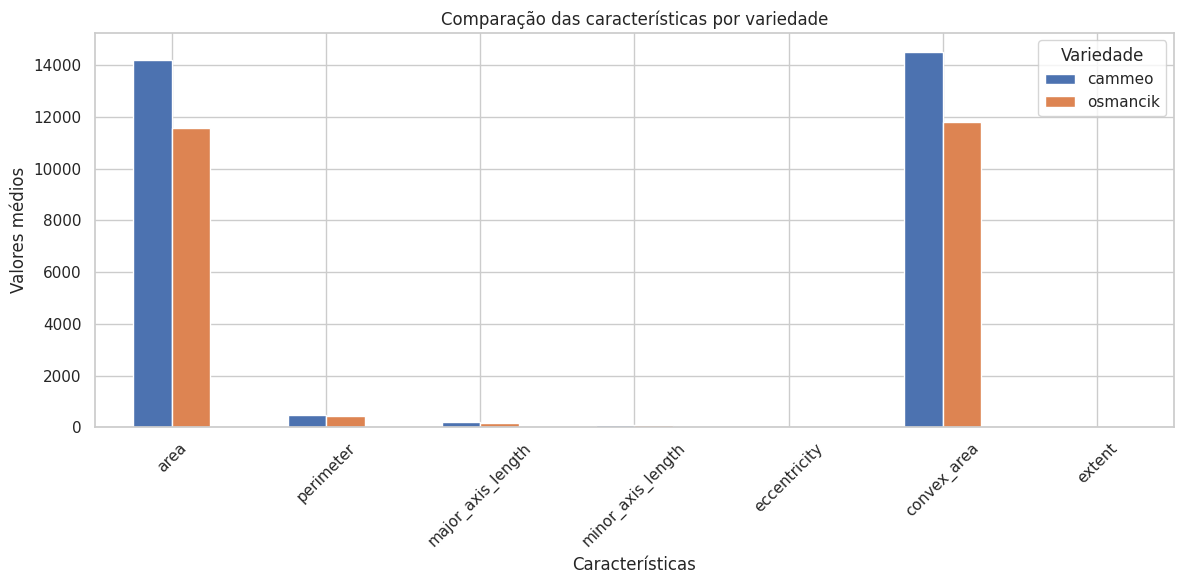

In [13]:
medias = df_train.groupby("variety").mean(numeric_only=True)

print("Médias das características por variedade:")
display(medias.round(2))

# Comparação das médias das características
medias.T.plot(kind="bar", figsize=(12, 6))

plt.title("Comparação das características por variedade")
plt.xlabel("Características")
plt.ylabel("Valores médios")
plt.xticks(rotation=45)
plt.legend(title="Variedade")
plt.tight_layout()

plt.show()

**Análise:**

A comparação mostrou que a variedade Cammeo apresenta valores maiores de área, perímetro, comprimento do eixo maior e área convexa.

As maiores diferenças aparecem na área e na área convexa. Essas características podem ajudar a diferenciar as duas variedades.

### Pergunta 8: Quais características numéricas apresentam maior correlação?

Foi utilizada uma matriz de correlação para comparar as características numéricas e identificar quais possuem relações mais fortes.

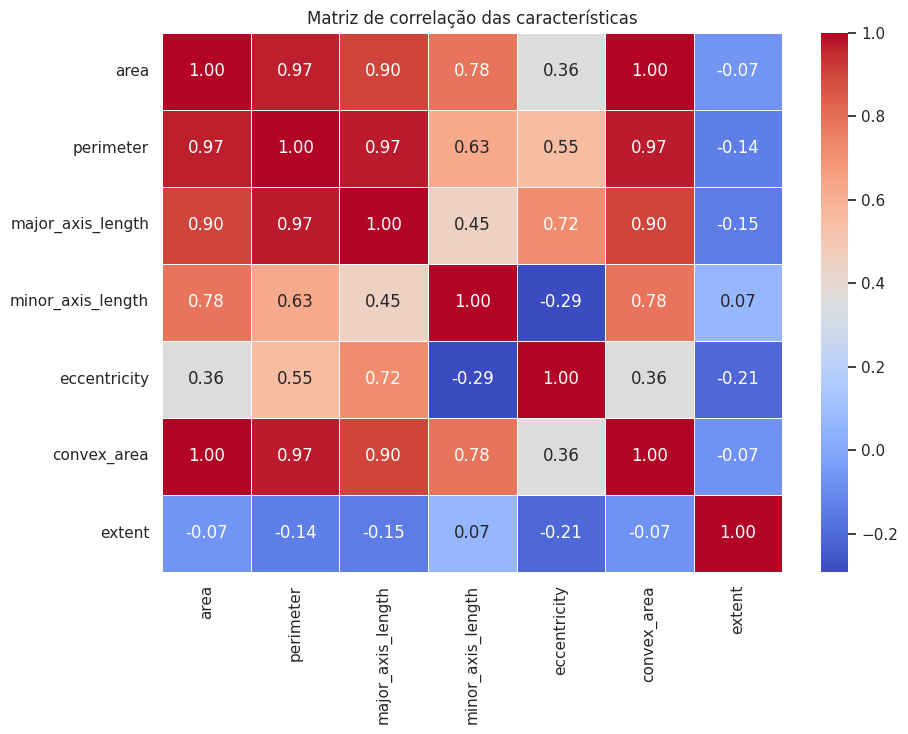

In [14]:
# Calcular a matriz de correlação
correlacao = df_train.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlação das características")
plt.show()

**Análise:**

A matriz mostra que algumas características possuem uma relação muito forte, principalmente a área e a área convexa, com correlação próxima de 1,00.

Também foi encontrada uma correlação forte entre área e perímetro, de aproximadamente 0,97.

Isso mostra que algumas características apresentam informações parecidas entre si, algo que pode ser levado em consideração na criação dos modelos.

## 2.9 Síntese da Análise Exploratória

Com as análises realizadas, foi possível observar algumas diferenças entre as variedades Cammeo e Osmancik.

Os grãos Cammeo apresentam, em média, maior área, perímetro e comprimento do eixo maior. Também foi possível perceber que algumas características possuem uma relação forte entre si, principalmente área e perímetro.

Outro ponto observado foi que a área e a área convexa apresentam uma correlação muito próxima de 1,00, indicando que essas duas características possuem informações bastante parecidas.

Como limitação, a base possui uma quantidade um pouco maior de registros da variedade Osmancik. Além disso, algumas características apresentam correlações elevadas.

De modo geral, as análises mostram que as características físicas dos grãos podem ajudar a diferenciar as duas variedades. Essas informações serão utilizadas na próxima etapa, durante a criação dos modelos de classificação.

# 3. Modelagem

Nesta etapa, foram utilizados modelos de aprendizado de máquina para tentar classificar os grãos de arroz nas variedades Cammeo e Osmancik.

Foram testados quatro modelos: Dummy Classifier, Decision Tree, Random Forest e SVM. Depois, os resultados foram comparados para verificar qual apresentou o melhor desempenho.

### 3.1 Separação dos atributos e da variável-alvo

Os dados já foram disponibilizados em dois arquivos separados pelo professor. O arquivo de treinamento foi utilizado para desenvolver e validar os modelos, enquanto o arquivo de teste ficou separado para a avaliação final.

A coluna variety representa a variedade do grão e será utilizada como resposta que o modelo precisa prever. As outras colunas numéricas serão utilizadas como informações para fazer essa previsão.

In [15]:
# Separar os atributos e a variável-alvo

X_train = df_train.drop(columns=["variety"])
y_train = df_train["variety"]

X_test = df_test.drop(columns=["variety"])
y_test = df_test["variety"]

# Conferir as dimensões
print("Atributos de treinamento:", X_train.shape)
print("Variável-alvo de treinamento:", y_train.shape)

print("Atributos de teste:", X_test.shape)
print("Variável-alvo de teste:", y_test.shape)

# Conferir as classes
print("\nClasses encontradas:")
print(y_train.unique())

Atributos de treinamento: (3048, 7)
Variável-alvo de treinamento: (3048,)
Atributos de teste: (762, 7)
Variável-alvo de teste: (762,)

Classes encontradas:
['osmancik' 'cammeo']


### 3.2 Prevenção de vazamento de dados

Para evitar que o modelo tenha acesso a informações dos dados de teste antes da avaliação final, esse conjunto foi mantido separado durante o treinamento e a validação.

Também foram utilizados pipelines para organizar as etapas de normalização e treinamento. Dessa forma, os cálculos da normalização são feitos somente com os dados utilizados em cada treinamento.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import StratifiedKFold, cross_validate

import pandas as pd
import numpy as np


In [17]:
# Modelo 1: Baseline
modelo_dummy = Pipeline([
    ("classificador", DummyClassifier(strategy="most_frequent"))
])

# Modelo 2: Árvore de Decisão
modelo_arvore = Pipeline([
    ("classificador", DecisionTreeClassifier(random_state=42))
])

# Modelo 3: Random Forest
modelo_floresta = Pipeline([
    ("classificador", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Modelo 4: SVM
modelo_svm = Pipeline([
    ("normalizacao", StandardScaler()),
    ("classificador", SVC())
])

# Organizar os modelos
modelos = {
    "Dummy Classifier": modelo_dummy,
    "Decision Tree": modelo_arvore,
    "Random Forest": modelo_floresta,
    "SVM": modelo_svm
}

print("Modelos preparados:")
for nome in modelos:
    print("-", nome)


Modelos preparados:
- Dummy Classifier
- Decision Tree
- Random Forest
- SVM


### 3.3 Validação cruzada

Foi utilizada a validação cruzada estratificada com cinco divisões. Esse método separa os dados em partes e permite avaliar os modelos em diferentes divisões, mantendo uma proporção parecida das duas variedades.

O valor random_state=42 foi mantido para que os resultados possam ser reproduzidos.

In [18]:
# Configurar validação cruzada
validacao = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Definir métricas
metricas = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

print("Validação cruzada configurada com 5 divisões.")


Validação cruzada configurada com 5 divisões.


In [19]:
# Armazenar os resultados
resultados = []

for nome, modelo in modelos.items():

    print(f"Avaliando: {nome}")

    resultado = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=validacao,
        scoring=metricas,
        n_jobs=-1
    )

    resultados.append({
        "Modelo": nome,
        "Acurácia": resultado["test_accuracy"].mean(),
        "Precisão": resultado["test_precision"].mean(),
        "Recall": resultado["test_recall"].mean(),
        "F1-score": resultado["test_f1"].mean()
    })

# Criar tabela comparativa
tabela_resultados = pd.DataFrame(resultados)

display(
    tabela_resultados.style.format({
        "Acurácia": "{:.4f}",
        "Precisão": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

Avaliando: Dummy Classifier
Avaliando: Decision Tree
Avaliando: Random Forest
Avaliando: SVM


,Modelo,Acurácia,Precisão,Recall,F1-score
0,Dummy Classifier,0.5722,0.2861,0.5000,0.3639
1,Decision Tree,0.8868,0.8844,0.8844,0.8844
2,Random Forest,0.9222,0.9212,0.9202,0.9205
3,SVM,0.9324,0.9313,0.9309,0.9310


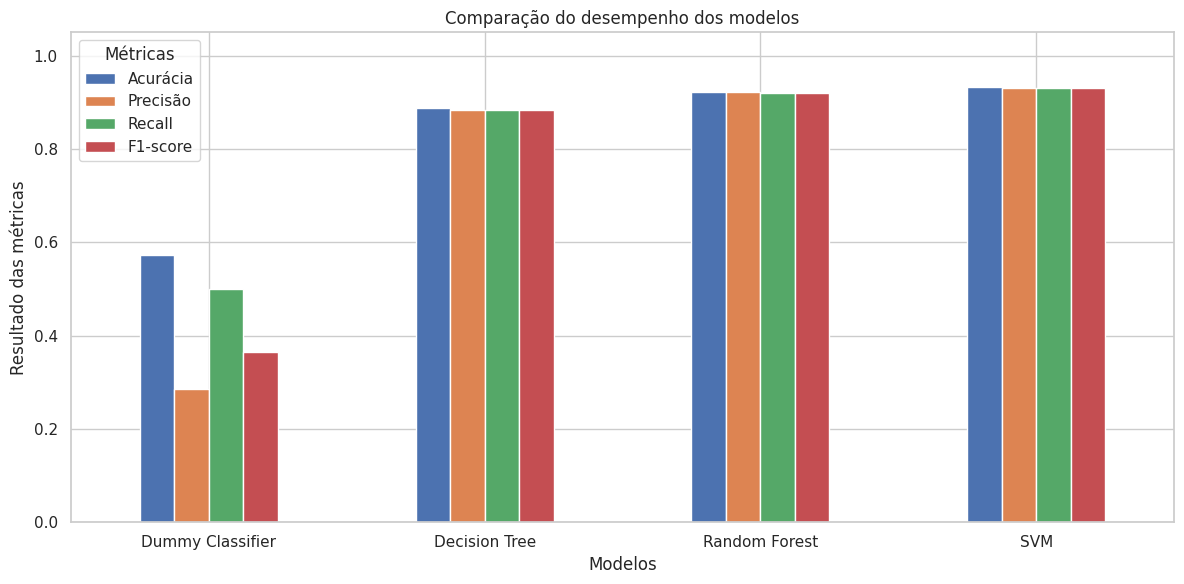

In [20]:
# Comparar as métricas dos modelos
tabela_grafico = tabela_resultados.set_index("Modelo")

tabela_grafico.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparação do desempenho dos modelos")
plt.xlabel("Modelos")
plt.ylabel("Resultado das métricas")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(title="Métricas")
plt.tight_layout()
plt.show()

### 3.4 Comparação inicial dos modelos

Os quatro modelos foram avaliados utilizando as mesmas divisões da validação cruzada.

O Dummy Classifier foi utilizado como uma comparação básica, pois não aprende os padrões dos dados. Os outros três modelos foram utilizados para verificar como conseguem classificar as variedades.

Foram analisadas quatro métricas: acurácia, precisão, recall e F1-score.

- **Acurácia:** mostra a porcentagem total de previsões corretas.
- **Precisão:** mostra quantas previsões de cada classe estavam corretas.
- **Recall:** mostra quantos exemplos reais de cada classe foram identificados corretamente.
- **F1-score:** combina precisão e recall em uma única medida.

### Comparação dos resultados

| Modelo | Acurácia | F1-score |
|---|---:|---:|
| Dummy Classifier | 57,22% | 36,39% |
| Decision Tree | 88,68% | 88,44% |
| Random Forest | 92,22% | 92,05% |
| SVM | 93,24% | 93,10% |

Análise dos resultados:

O Dummy Classifier apresentou o menor resultado, com 57,22% de acurácia. Ele serviu como uma comparação básica para os outros modelos, pois apenas prevê a classe mais frequente.

A Árvore de Decisão alcançou 88,68% de acurácia, enquanto o Random Forest chegou a 92,22%.

O SVM apresentou o melhor resultado, com 93,24% de acurácia e 93,10% de F1-score. Por isso, ele foi escolhido para a próxima etapa de ajuste.

## 4. Ajuste de hiperparâmetros

Depois de comparar os modelos, foi realizado um ajuste no SVM para tentar encontrar uma configuração que apresentasse um resultado melhor.

Para isso, foi utilizado o GridSearchCV, que testa diferentes combinações de parâmetros e compara os resultados utilizando validação cruzada.

A busca foi feita somente com os dados de treinamento, mantendo o conjunto de teste separado.

In [21]:
from sklearn.model_selection import GridSearchCV

# Definição dos parâmetros que serão testados
parametros = {
    "classificador__C": [0.1, 1, 10, 100],
    "classificador__kernel": ["linear", "rbf"],
    "classificador__gamma": ["scale", "auto", 0.01, 0.1, 1]
}

# Criação da busca de parâmetros
busca_svm = GridSearchCV(
    estimator=modelo_svm,
    param_grid=parametros,
    cv=validacao,
    scoring="f1_macro",
    n_jobs=-1
)

# Treinamento e busca dos melhores parâmetros
busca_svm.fit(X_train, y_train)

print("Melhores parâmetros:")
print(busca_svm.best_params_)

print("\nMelhor F1-score:")
print(busca_svm.best_score_)

Melhores parâmetros:
{'classificador__C': 10, 'classificador__gamma': 'scale', 'classificador__kernel': 'linear'}

Melhor F1-score:
0.9326596326086051


Análise do ajuste de hiperparâmetros

A melhor configuração encontrada foi C=10, gamma='scale' e kernel='linear'.

Com esses parâmetros, o modelo alcançou um F1-score de aproximadamente 93,27% na validação cruzada.

O resultado foi um pouco melhor que o SVM inicial, que havia alcançado 93,10% de F1-score. Por isso, essa configuração foi utilizada na avaliação final.

## 5. Avaliação final do modelo

Nesta etapa, o SVM ajustado foi testado utilizando os dados do arquivo rice_test.csv, que possui 762 registros.

Foram analisadas as métricas de acurácia, precisão, recall e F1-score, além da matriz de confusão.

RESULTADOS NO CONJUNTO DE TESTE
Acurácia: 0.9186
Precisão: 0.9193
Recall: 0.9142
F1-score: 0.9164

Relatório de classificação:
              precision    recall  f1-score   support

      cammeo       0.92      0.88      0.90       326
    osmancik       0.92      0.94      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.92       762
weighted avg       0.92      0.92      0.92       762



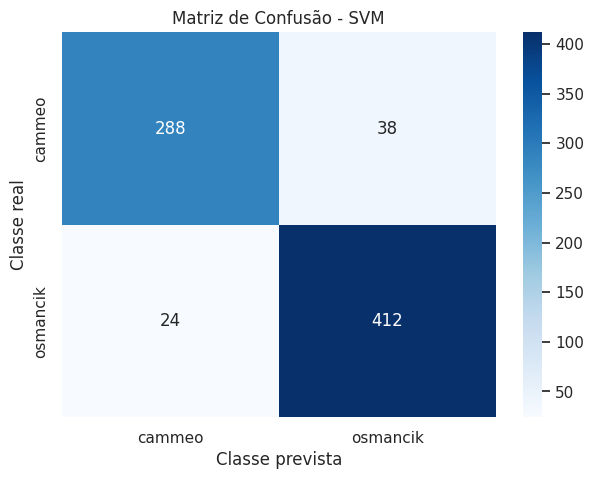

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Utilizar o melhor modelo encontrado pelo GridSearchCV
melhor_svm = busca_svm.best_estimator_

# Fazer previsões com os dados de teste
y_pred = melhor_svm.predict(X_test)

# Calcular as métricas
print("RESULTADOS NO CONJUNTO DE TESTE")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão: {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall: {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

# Criar matriz de confusão
matriz = confusion_matrix(y_test, y_pred, labels=melhor_svm.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=melhor_svm.classes_,
    yticklabels=melhor_svm.classes_
)

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de Confusão - SVM")
plt.show()

Análise da avaliação final

Na avaliação com os dados de teste, o modelo SVM alcançou 91,86% de acurácia e 91,64% de F1-score.

Analisando cada variedade, o modelo obteve F1-score de 90% para Cammeo e 93% para Osmancik.

Os resultados mostram que o modelo conseguiu classificar corretamente a maioria dos grãos. Porém, teve um pouco mais de dificuldade para identificar Cammeo, que apresentou recall de 88%, enquanto Osmancik alcançou 94%.

Mesmo com essa diferença, o resultado geral foi bom, mostrando que o SVM conseguiu identificar as duas variedades com um desempenho próximo de 92%.

##  6. Conclusão

O objetivo deste projeto foi utilizar aprendizado de máquina para classificar grãos de arroz das variedades Cammeo e Osmancik, utilizando suas características físicas.

Primeiro, foi feita uma análise dos dados para entender melhor as características dos grãos e observar as diferenças entre as duas variedades.

Depois, foram testados quatro modelos: Dummy Classifier, Decision Tree, Random Forest e SVM. Entre eles, o SVM apresentou o melhor resultado na validação cruzada, com 93,10% de F1-score.

Em seguida, foi feito o ajuste dos parâmetros do SVM utilizando GridSearchCV. Com isso, o F1-score chegou a aproximadamente 93,27% na validação cruzada.

Na avaliação final, utilizando os dados de teste, o modelo alcançou 91,86% de acurácia e 91,64% de F1-score. Ele apresentou um resultado um pouco melhor na identificação da variedade Osmancik do que na Cammeo.

Com os resultados, foi possível perceber que o aprendizado de máquina consegue ajudar na identificação das variedades de arroz utilizando características físicas dos grãos.

Como melhoria para o projeto, poderiam ser testados outros modelos e configurações para tentar melhorar os resultados da classificação.